<a href="https://colab.research.google.com/github/donggeunlee77/R-exercise/blob/main/R_Multinomial_Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Multinomial Logistic Regression with R

https://stats.oarc.ucla.edu/r/dae/multinomial-logistic-regression/

In [1]:
install.packages("foreign")
install.packages("nnet")
install.packages("ggplot2")
install.packages("reshape2")
require(foreign)
require(nnet)
require(ggplot2)
require(reshape2)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependency ‘plyr’


Loading required package: foreign

Loading required package: nnet

Loading required package: ggplot2

Loading required package: reshape2



In [2]:
ml <- read.dta("https://stats.idre.ucla.edu/stat/data/hsbdemo.dta")

In [3]:
head(ml)

,id,female,ses,schtyp,prog,read,write,math,science,socst,honors,awards,cid
,<dbl>,<fct>,<fct>,<fct>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<dbl>,<int>
1,45,female,low,public,vocation,34,35,41,29,26,not enrolled,0,1
2,108,male,middle,public,general,34,33,41,36,36,not enrolled,0,1
3,15,male,high,public,vocation,39,39,44,26,42,not enrolled,0,1
4,67,male,low,public,vocation,37,37,42,33,32,not enrolled,0,1
5,153,male,middle,public,vocation,39,31,40,39,51,not enrolled,0,1
6,51,female,high,public,general,42,36,42,31,39,not enrolled,0,1


In [4]:
summary(ml)

       id            female        ses         schtyp          prog    
 Min.   :  1.00   male  : 91   low   :47   public :168   general : 45  
 1st Qu.: 50.75   female:109   middle:95   private: 32   academic:105  
 Median :100.50                high  :58                 vocation: 50  
 Mean   :100.50                                                        
 3rd Qu.:150.25                                                        
 Max.   :200.00                                                        
      read           write            math          science     
 Min.   :28.00   Min.   :31.00   Min.   :33.00   Min.   :26.00  
 1st Qu.:44.00   1st Qu.:45.75   1st Qu.:45.00   1st Qu.:44.00  
 Median :50.00   Median :54.00   Median :52.00   Median :53.00  
 Mean   :52.23   Mean   :52.77   Mean   :52.65   Mean   :51.85  
 3rd Qu.:60.00   3rd Qu.:60.00   3rd Qu.:59.00   3rd Qu.:58.00  
 Max.   :76.00   Max.   :67.00   Max.   :75.00   Max.   :74.00  
     socst                honors        a

In [7]:
with(ml, table(ses, prog))

        prog
ses      general academic vocation
  low         16       19       12
  middle      20       44       31
  high         9       42        7

In [10]:
with(ml, do.call(rbind, tapply(write, prog, function(x) c(M = mean(x), SD = sd(x)))))

,M,SD
general,51.33333,9.397775
academic,56.25714,7.943343
vocation,46.76000,9.318754


tapply(데이터, 그룹변수, 적용할 함수) -> 그룹별로 특정 함수를 적용하는 함수. 여기서 c(~) 이거는 두 개의 결과를 하나의 벡터로 묶는 명령어.

do.call()은 함수에 인수를 전달해서 실행하는 함수
rbind()는 row(행) 방향으로 데이터를 결합하는 함수.

do.call(rbind, ...)는 결과적으로

rbind(그룹 1 결과, 그룹 2 결과, 그룹 3 결과)

이런 작업을 수행.

prog를 예측하기 위해 multinomial logistic regression을 사용할거고, nnet package의 multinom 함수를 사용할건데 얘는 p-value calculation 이 포함이 안돼있어서 직접 Wald tests (z-tests)를 사용해서 p value를 계산할 것.

In [14]:
class(ml$prog)

[1] "factor"

In [15]:
levels(ml$prog)

[1] "general"  "academic" "vocation"

In [17]:
ml$prog2 <- relevel(ml$prog, ref = 'academic')

In [18]:
levels(ml$prog2)

[1] "academic" "general"  "vocation"

이렇게 baseline이 될 level을 재설정하였음.

In [19]:
test <- multinom(prog2 ~ ses + write, data = ml)

# weights:  15 (8 variable)
initial  value 219.722458 
iter  10 value 179.982880
final  value 179.981726 
converged


In [20]:
test

Call:
multinom(formula = prog2 ~ ses + write, data = ml)

Coefficients:
         (Intercept)  sesmiddle    seshigh      write
general     2.852198 -0.5332810 -1.1628226 -0.0579287
vocation    5.218260  0.2913859 -0.9826649 -0.1136037

Residual Deviance: 359.9635 
AIC: 375.9635 

In [21]:
summary(test)

Call:
multinom(formula = prog2 ~ ses + write, data = ml)

Coefficients:
         (Intercept)  sesmiddle    seshigh      write
general     2.852198 -0.5332810 -1.1628226 -0.0579287
vocation    5.218260  0.2913859 -0.9826649 -0.1136037

Std. Errors:
         (Intercept) sesmiddle   seshigh      write
general     1.166441 0.4437323 0.5142196 0.02141097
vocation    1.163552 0.4763739 0.5955665 0.02221996

Residual Deviance: 359.9635 
AIC: 375.9635 

In [22]:
z <- summary(test)$coefficients/summary(test)$standard.errors

회귀계수 ÷ 표준오차 → Z 통계량 계산

In [23]:
z

,(Intercept),sesmiddle,seshigh,write
general,2.445214,-1.2018081,-2.261334,-2.705562
vocation,4.484769,0.6116747,-1.649967,-5.112689


2-tailed z test 구하기

In [24]:
p <- (1 - pnorm(abs(z), 0, 1)) * 2
p

,(Intercept),sesmiddle,seshigh,write
general,0.0144766100,0.2294379,0.02373856,6.818902e-03
vocation,0.0000072993,0.5407530,0.09894976,3.176045e-07


In [25]:
p2 <- 2 * pnorm(abs(z), lower.tail = FALSE)
p2

,(Intercept),sesmiddle,seshigh,write
general,0.0144766100,0.2294379,0.02373856,6.818902e-03
vocation,0.0000072993,0.5407530,0.09894976,3.176045e-07


pnorm은 정규분포의 누적분포함수인데, pnorm(q, mean, sd) 형태로 q = 계산하려는 z값을 의미. 따라서 위의 pnorm 내부는 표준정규분포에서 해당 Z값의 왼쪽에 존재하는 누적확률.(P(Z <= |z|)

1- pnorm은 오른쪽 꼬리 확률, 그걸 두배 하면 양측검정이 됨

p <- 2 * pnorm(abs(z), lower.tail = FALSE)

이 코드도 완전히 동일한 역할.

In [26]:
exp(coef(test))

,(Intercept),sesmiddle,seshigh,write
general,17.32582,0.5866769,0.3126026,0.9437172
vocation,184.61262,1.3382809,0.3743123,0.8926116


다음으로, calculate predicted probabilities using fitted 함수

In [27]:
head(pp <- fitted(test))

,academic,general,vocation
1,0.1482764,0.3382454,0.5134781
2,0.1202017,0.1806283,0.6991700
3,0.4186747,0.2368082,0.3445171
4,0.1726885,0.3508384,0.4764731
5,0.1001231,0.1689374,0.7309395
6,0.3533566,0.2377976,0.4088458


In [28]:
##write를 평균값으로 고정했을때 ses의 각 level별 예측 확률을 계산해보자

dses <- data.frame(ses = c("low", "middle", "high"), write = mean(ml$write))

In [29]:
predict(test, newdata = dses, "probs")

,academic,general,vocation
1,0.4396845,0.3581917,0.2021238
2,0.4777488,0.2283353,0.2939159
3,0.7009007,0.1784939,0.1206054


In [31]:
## ses의 각 level별로 averaged predicted probability를 계산해보자

dwrite <- data.frame(ses = rep(c("low", "middle", "high"), each = 41), write = rep(c(30:70), 3))
head(dwrite)

,ses,write
,<chr>,<int>
1,low,30
2,low,31
3,low,32
4,low,33
5,low,34
6,low,35


In [32]:
pp.write <- cbind(dwrite, predict(test, newdata = dwrite, type='probs', se=TRUE))
head(pp.write)

,ses,write,academic,general,vocation
,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,low,30,0.09843588,0.2999880,0.6015762
2,low,31,0.10716868,0.3082195,0.5846118
3,low,32,0.11650390,0.3162093,0.5672868
4,low,33,0.12645834,0.3239094,0.5496323
5,low,34,0.13704576,0.3312711,0.5316831
6,low,35,0.14827643,0.3382454,0.5134781


In [33]:
by(pp.write[,3:5], pp.write$ses, colMeans)

pp.write$ses: high
 academic   general  vocation 
0.6164315 0.1808037 0.2027648 
------------------------------------------------------------ 
pp.write$ses: low
 academic   general  vocation 
0.3972977 0.3278174 0.2748849 
------------------------------------------------------------ 
pp.write$ses: middle
 academic   general  vocation 
0.4256198 0.2010864 0.3732938 

by(데이터, 그룹변수, 적용할 함수) 의 구조로 이루어짐.

tapply는 그룹별로 특정 변수에 함수 적용, by는 그룹별로 데이터 전체 또는 일부에 함수 적용..?

다음으론 그래프를 그려보기 위해 함수를 melt 시켜보자.

In [35]:
lpp <- melt(pp.write, id.vars = c("ses", "write"), value.name = "probability")
head(lpp)

,ses,write,variable,probability
,<chr>,<int>,<fct>,<dbl>
1,low,30,academic,0.09843588
2,low,31,academic,0.10716868
3,low,32,academic,0.11650390
4,low,33,academic,0.12645834
5,low,34,academic,0.13704576
6,low,35,academic,0.14827643


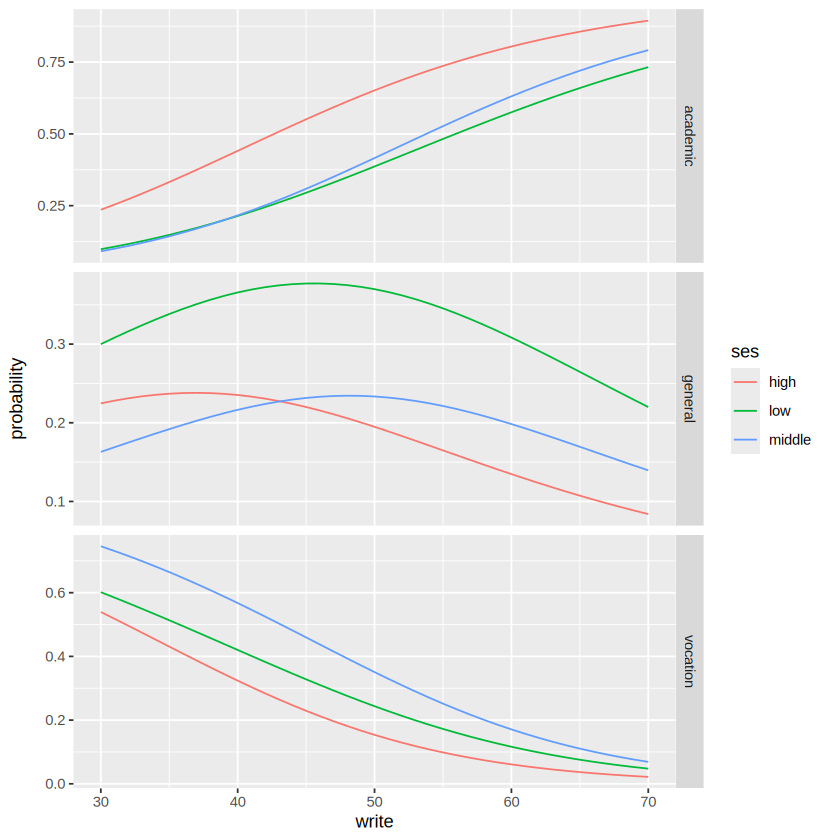

In [37]:
ggplot(lpp, aes(x=write, y=probability, colour=ses))+
  geom_line()+
  facet_grid(variable~., scales = 'free')

# Things to consider

The Independence of Irrelevant Alternatives (IIA) assumption: Roughly,
the IIA assumption means that adding or deleting alternative outcome
categories does not affect the odds among the remaining outcomes. 예를들면 사과 배 오렌지 를 예측하고 있는데, 추가로 수박 이라는 새로운 outcome category가 새로 추가된다고 해도, 그렇다고 사과와 배 사이의 선호에 대한 비율(OR)은 변하지 않는다는것. There are
alternative modeling methods, such as alternative-specific multinomial probit model, or nested logit model to relax the IIA assumption.


Diagnostics and model fit: Unlike logistic regression where there are many
statistics for performing model diagnostics, it is not as straightforward to
do diagnostics with multinomial logistic regression models. For the purpose of detecting outliers or influential data points, one can
run separate logit models and use the diagnostics tools on each model.